In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
x, t = (761,500)

In [3]:
data_folder = Path('data')

In [4]:
df_l = pd.read_csv('files/xt.csv')
l = df_l[(df_l['x'] == x) & (df_l['t'] == t)]
l = l["label"].iloc[0]
df_rk = pd.read_csv('files/xt_ripley.csv')
rk = df_rk[(df_rk['x'] == x) & (df_rk['t'] == t)]
df_ap = pd.read_csv('files/xt_alpha.csv')
ap = df_ap[(df_ap['x'] == x) & (df_ap['t'] == t)]
df_cap = pd.read_csv('files/xt_calpha.csv')
cap = df_cap[(df_cap['x'] == x) & (df_cap['t'] == t)]
df_sp = pd.read_csv('files/xt_sixpack.csv')
sp = df_sp[(df_sp['x'] == x) & (df_sp['t'] == t)]

In [5]:
x_vector = np.arange(0, 10, 0.2)

# Analysis of the selected image

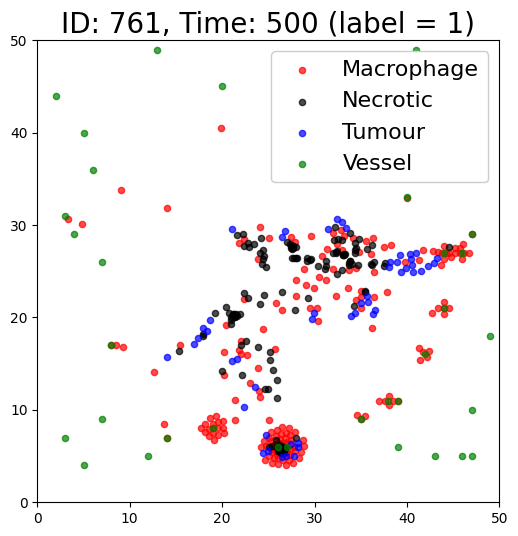

In [6]:
filename = f'ID-{x}_time-{t}_From2ParamSweep_Data.csv'
file_path = data_folder / filename
df = pd.read_csv(file_path)   
keep_types = [
    'Tumour', 
    'Macrophage', 
    'Vessel',
    'Necrotic'
]
filtered_df = df[df['celltypes'].isin(keep_types)]
color_map = {
    'Vessel': 'green',
    'Macrophage': 'red',
    'Tumour': 'blue',
    'Necrotic': 'black'
}
fig, ax = plt.subplots(figsize=(6, 6))
for celltype, group in filtered_df.groupby('celltypes'):
    ax.scatter(
        group['points_x'],
        group['points_y'],
        label=celltype,
        alpha=0.7,
        s=20,
        color=color_map[celltype]
    )
ax.set_title(f'ID: {x}, Time: {t} (label = {l})', fontsize=20)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_xlim(0, 50)
ax.set_ylim(0, 50)
ax.legend(fontsize=16, framealpha=1.0)
ax.set_aspect('equal')
plt.savefig(f'plots/id_{x}_t_{t}_dataset.pdf')
plt.show()

### Fuzzy Betti curves of Alpha complexes for pairs of classes

In [7]:
colors = ['purple', 'blue', 'red', 'green']

In [8]:
MT0 = np.vstack([
    ap.iloc[0,3:53].to_numpy(),
    ap.iloc[0,53:103].to_numpy(),
    ap.iloc[0,103:153].to_numpy(),
    ap.iloc[0,153:203].to_numpy()
])
MT1 = np.vstack([
    ap.iloc[0,203:253].to_numpy(),
    ap.iloc[0,253:303].to_numpy(),
    ap.iloc[0,303:353].to_numpy(),
    ap.iloc[0,353:403].to_numpy()
])

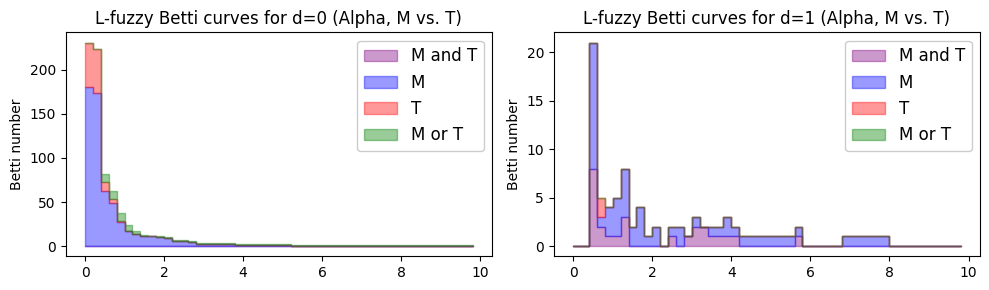

In [9]:
labels = ['M and T', 'M', 'T', 'M or T']
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

cumulative = np.zeros(50)
for i in range(4):
    new_cumulative = cumulative + MT0[i]
    axes[0].fill_between(x_vector, cumulative, new_cumulative, color=colors[i], alpha=0.4, label=labels[i],step='post')
    cumulative = new_cumulative
axes[0].set_title('L-fuzzy Betti curves for d=0 (Alpha, M vs. T)')
axes[0].set_xlabel('')
axes[0].set_ylabel('Betti number')
axes[0].legend(fontsize=12, framealpha=1.0)

cumulative = np.zeros(50)
for i in range(4):
    new_cumulative = cumulative + MT1[i]
    axes[1].fill_between(x_vector, cumulative, new_cumulative, color=colors[i], alpha=0.4, label=labels[i],step='post')
    cumulative = new_cumulative
axes[1].set_title('L-fuzzy Betti curves for d=1 (Alpha, M vs. T)')
axes[1].set_xlabel('')
axes[1].set_ylabel('Betti number')
axes[1].legend(fontsize=12, framealpha=1.0)

plt.tight_layout()
plt.savefig(f'plots/id_{x}_t_{t}_mt_alpha.pdf')
plt.show()

In [10]:
TV0 = np.vstack([
    ap.iloc[0,403:453].to_numpy(),
    ap.iloc[0,453:503].to_numpy(),
    ap.iloc[0,503:553].to_numpy(),
    ap.iloc[0,553:603].to_numpy()
])
TV1 = np.vstack([
    ap.iloc[0,603:653].to_numpy(),
    ap.iloc[0,653:703].to_numpy(),
    ap.iloc[0,703:753].to_numpy(),
    ap.iloc[0,753:803].to_numpy()
])

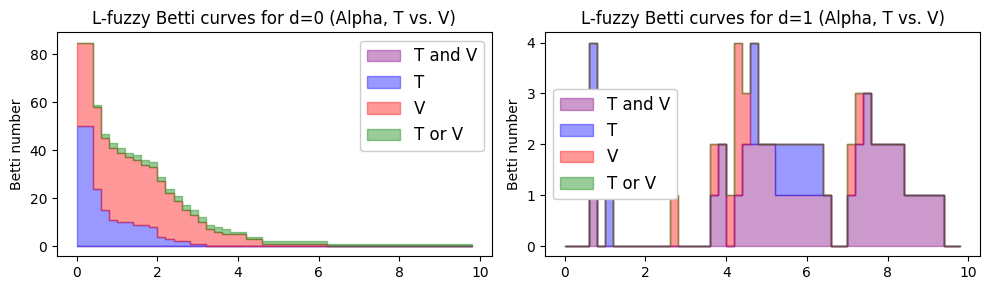

In [11]:
labels = ['T and V', 'T', 'V', 'T or V']
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

cumulative = np.zeros(50)
for i in range(4):
    new_cumulative = cumulative + TV0[i]
    axes[0].fill_between(x_vector, cumulative, new_cumulative, color=colors[i], alpha=0.4, label=labels[i],step='post')
    cumulative = new_cumulative
axes[0].set_title('L-fuzzy Betti curves for d=0 (Alpha, T vs. V)')
axes[0].set_xlabel('')
axes[0].set_ylabel('Betti number')
axes[0].legend(fontsize=12, framealpha=1.0)

cumulative = np.zeros(50)
for i in range(4):
    new_cumulative = cumulative + TV1[i]
    axes[1].fill_between(x_vector, cumulative, new_cumulative, color=colors[i], alpha=0.4, label=labels[i],step='post')
    cumulative = new_cumulative
axes[1].set_title('L-fuzzy Betti curves for d=1 (Alpha, T vs. V)')
axes[1].set_xlabel('')
axes[1].set_ylabel('Betti number')
axes[1].legend(fontsize=12, framealpha=1.0)

plt.tight_layout()
plt.savefig(f'plots/id_{x}_t_{t}_tv_alpha.pdf')
plt.show()

In [12]:
MV0 = np.vstack([
    ap.iloc[0,803:853].to_numpy(),
    ap.iloc[0,853:903].to_numpy(),
    ap.iloc[0,903:953].to_numpy(),
    ap.iloc[0,953:1003].to_numpy()
])
MV1 = np.vstack([
    ap.iloc[0,1003:1053].to_numpy(),
    ap.iloc[0,1053:1103].to_numpy(),
    ap.iloc[0,1103:1153].to_numpy(),
    ap.iloc[0,1153:1203].to_numpy()
])

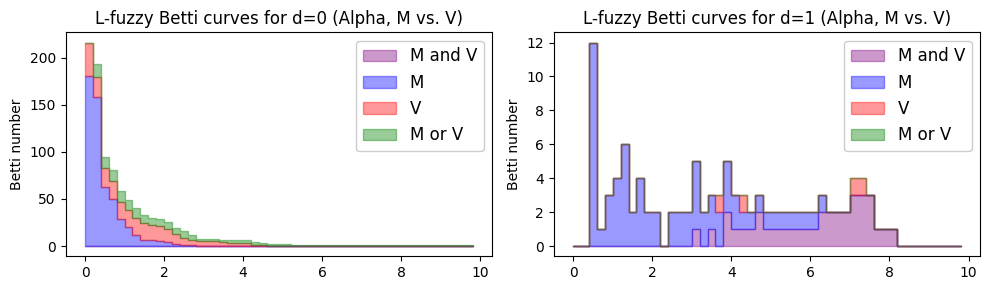

In [13]:
labels = ['M and V', 'M', 'V', 'M or V']
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

cumulative = np.zeros(50)
for i in range(4):
    new_cumulative = cumulative + MV0[i]
    axes[0].fill_between(x_vector, cumulative, new_cumulative, color=colors[i], alpha=0.4, label=labels[i],step='post')
    cumulative = new_cumulative
axes[0].set_title('L-fuzzy Betti curves for d=0 (Alpha, M vs. V)')
axes[0].set_xlabel('')
axes[0].set_ylabel('Betti number')
axes[0].legend(fontsize=12, framealpha=1.0)

cumulative = np.zeros(50)
for i in range(4):
    new_cumulative = cumulative + MV1[i]
    axes[1].fill_between(x_vector, cumulative, new_cumulative, color=colors[i], alpha=0.4, label=labels[i],step='post')
    cumulative = new_cumulative
axes[1].set_title('L-fuzzy Betti curves for d=1 (Alpha, M vs. V)')
axes[1].set_xlabel('')
axes[1].set_ylabel('Betti number')
axes[1].legend(fontsize=12, framealpha=1.0)

plt.tight_layout()
plt.savefig(f'plots/id_{x}_t_{t}_mv_alpha.pdf')
plt.show()

### Fuzzy Betti curves of Chromatic Alpha complexes for pairs of classes

In [14]:
MT0 = np.vstack([
    cap.iloc[0,3:53].to_numpy(),
    cap.iloc[0,53:103].to_numpy(),
    cap.iloc[0,103:153].to_numpy(),
    cap.iloc[0,153:203].to_numpy()
])
MT1 = np.vstack([
    cap.iloc[0,203:253].to_numpy(),
    cap.iloc[0,253:303].to_numpy(),
    cap.iloc[0,303:353].to_numpy(),
    cap.iloc[0,353:403].to_numpy()
])

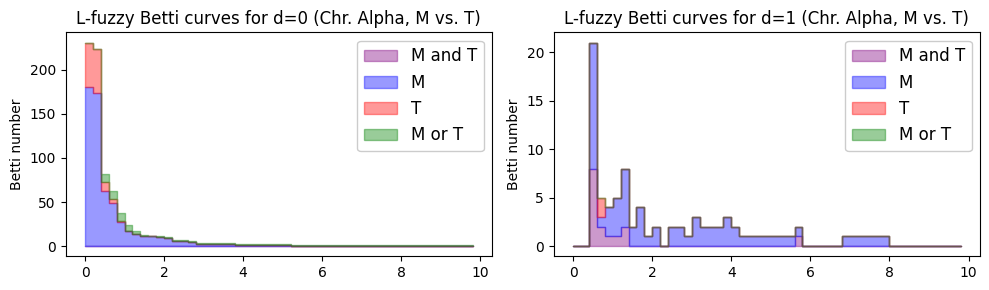

In [15]:
labels = ['M and T', 'M', 'T', 'M or T']
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

cumulative = np.zeros(50)
for i in range(4):
    new_cumulative = cumulative + MT0[i]
    axes[0].fill_between(x_vector, cumulative, new_cumulative, color=colors[i], alpha=0.4, label=labels[i],step='post')
    cumulative = new_cumulative
axes[0].set_title('L-fuzzy Betti curves for d=0 (Chr. Alpha, M vs. T)')
axes[0].set_xlabel('')
axes[0].set_ylabel('Betti number')
axes[0].legend(fontsize=12, framealpha=1.0)

cumulative = np.zeros(50)
for i in range(4):
    new_cumulative = cumulative + MT1[i]
    axes[1].fill_between(x_vector, cumulative, new_cumulative, color=colors[i], alpha=0.4, label=labels[i],step='post')
    cumulative = new_cumulative
axes[1].set_title('L-fuzzy Betti curves for d=1 (Chr. Alpha, M vs. T)')
axes[1].set_xlabel('')
axes[1].set_ylabel('Betti number')
axes[1].legend(fontsize=12, framealpha=1.0)

plt.tight_layout()
plt.savefig(f'plots/id_{x}_t_{t}_mt_calpha.pdf')
plt.show()

In [16]:
TV0 = np.vstack([
    cap.iloc[0,403:453].to_numpy(),
    cap.iloc[0,453:503].to_numpy(),
    cap.iloc[0,503:553].to_numpy(),
    cap.iloc[0,553:603].to_numpy()
])
TV1 = np.vstack([
    cap.iloc[0,603:653].to_numpy(),
    cap.iloc[0,653:703].to_numpy(),
    cap.iloc[0,703:753].to_numpy(),
    cap.iloc[0,753:803].to_numpy()
])

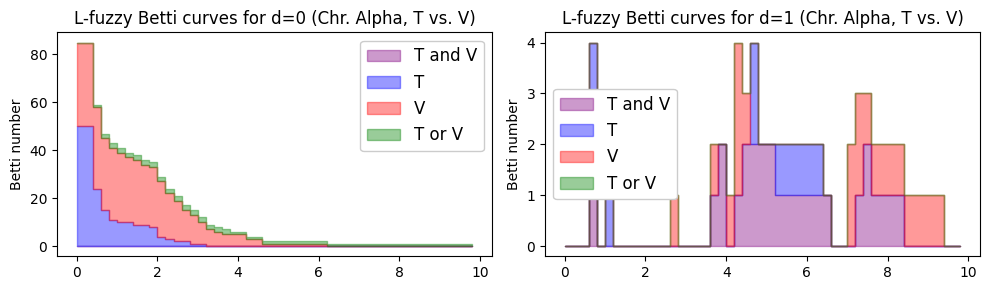

In [17]:
labels = ['T and V', 'T', 'V', 'T or V']
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

cumulative = np.zeros(50)
for i in range(4):
    new_cumulative = cumulative + TV0[i]
    axes[0].fill_between(x_vector, cumulative, new_cumulative, color=colors[i], alpha=0.4, label=labels[i],step='post')
    cumulative = new_cumulative
axes[0].set_title('L-fuzzy Betti curves for d=0 (Chr. Alpha, T vs. V)')
axes[0].set_xlabel('')
axes[0].set_ylabel('Betti number')
axes[0].legend(fontsize=12, framealpha=1.0)

cumulative = np.zeros(50)
for i in range(4):
    new_cumulative = cumulative + TV1[i]
    axes[1].fill_between(x_vector, cumulative, new_cumulative, color=colors[i], alpha=0.4, label=labels[i],step='post')
    cumulative = new_cumulative
axes[1].set_title('L-fuzzy Betti curves for d=1 (Chr. Alpha, T vs. V)')
axes[1].set_xlabel('')
axes[1].set_ylabel('Betti number')
axes[1].legend(fontsize=12, framealpha=1.0)

plt.tight_layout()
plt.savefig(f'plots/id_{x}_t_{t}_tv_calpha.pdf')
plt.show()

In [18]:
MV0 = np.vstack([
    cap.iloc[0,803:853].to_numpy(),
    cap.iloc[0,853:903].to_numpy(),
    cap.iloc[0,903:953].to_numpy(),
    cap.iloc[0,953:1003].to_numpy()
])
MV1 = np.vstack([
    cap.iloc[0,1003:1053].to_numpy(),
    cap.iloc[0,1053:1103].to_numpy(),
    cap.iloc[0,1103:1153].to_numpy(),
    cap.iloc[0,1153:1203].to_numpy()
])

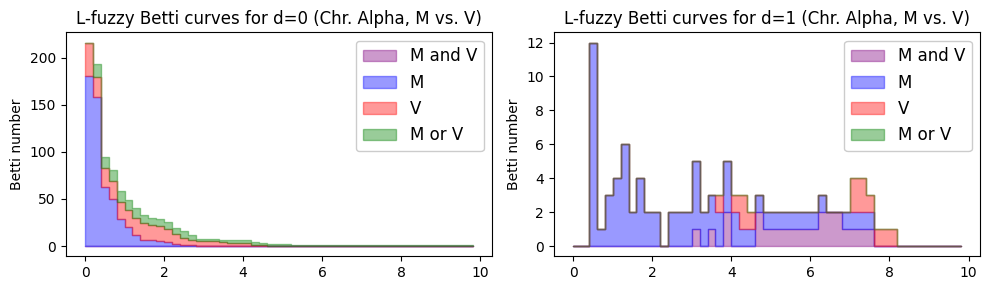

In [19]:
labels = ['M and V', 'M', 'V', 'M or V']
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

cumulative = np.zeros(50)
for i in range(4):
    new_cumulative = cumulative + MV0[i]
    axes[0].fill_between(x_vector, cumulative, new_cumulative, color=colors[i], alpha=0.4, label=labels[i],step='post')
    cumulative = new_cumulative
axes[0].set_title('L-fuzzy Betti curves for d=0 (Chr. Alpha, M vs. V)')
axes[0].set_xlabel('')
axes[0].set_ylabel('Betti number')
axes[0].legend(fontsize=12, framealpha=1.0)

cumulative = np.zeros(50)
for i in range(4):
    new_cumulative = cumulative + MV1[i]
    axes[1].fill_between(x_vector, cumulative, new_cumulative, color=colors[i], alpha=0.4, label=labels[i],step='post')
    cumulative = new_cumulative
axes[1].set_title('L-fuzzy Betti curves for d=1 (Chr. Alpha, M vs. V)')
axes[1].set_xlabel('')
axes[1].set_ylabel('Betti number')
axes[1].legend(fontsize=12, framealpha=1.0)

plt.tight_layout()
plt.savefig(f'plots/id_{x}_t_{t}_mv_calpha.pdf')
plt.show()

### Betti curves of Six-pack diagrams for pairs of classes

In [20]:
colors = ['purple', 'blue', 'red', 'green','black','brown']

In [21]:
MT0 = np.vstack([
    sp.iloc[0,3:53].to_numpy(),
    sp.iloc[0,53:103].to_numpy(),
    sp.iloc[0,103:153].to_numpy(),
    sp.iloc[0,153:203].to_numpy(),
    sp.iloc[0,203:253].to_numpy(),
    sp.iloc[0,253:303].to_numpy()
])
MT1 = np.vstack([
    sp.iloc[0,303:353].to_numpy(),
    sp.iloc[0,353:403].to_numpy(),
    sp.iloc[0,403:453].to_numpy(),
    sp.iloc[0,453:503].to_numpy(),
    sp.iloc[0,503:553].to_numpy(),
    sp.iloc[0,553:603].to_numpy()
])

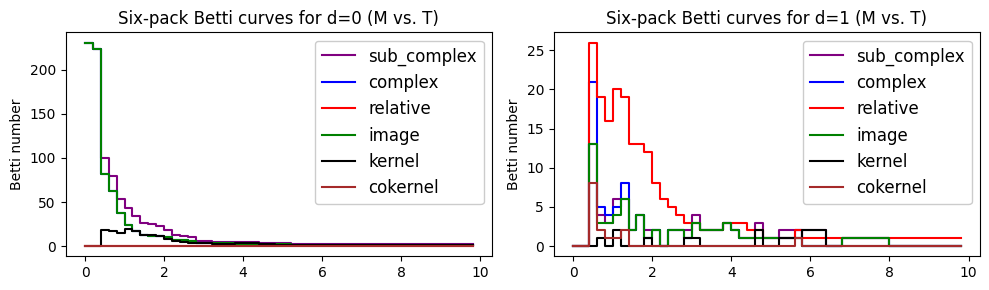

In [22]:
labels = ['sub_complex','complex','relative','image','kernel','cokernel']
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

for i in range(6):
    axes[0].step(x_vector, MT0[i], where="post", color=colors[i], label=labels[i])
axes[0].set_title('Six-pack Betti curves for d=0 (M vs. T)')
axes[0].set_xlabel('')
axes[0].set_ylabel('Betti number')
axes[0].legend(fontsize=12, framealpha=1.0)

for i in range(6):
    axes[1].step(x_vector, MT1[i], where="post", color=colors[i], label=labels[i])
axes[1].set_title('Six-pack Betti curves for d=1 (M vs. T)')
axes[1].set_xlabel('')
axes[1].set_ylabel('Betti number')
axes[1].legend(fontsize=12, framealpha=1.0)

plt.tight_layout()
plt.savefig(f'plots/id_{x}_t_{t}_mt_sixpack.pdf')
plt.show()

In [23]:
TV0 = np.vstack([
    sp.iloc[0,603:653].to_numpy(),
    sp.iloc[0,653:703].to_numpy(),
    sp.iloc[0,703:753].to_numpy(),
    sp.iloc[0,753:803].to_numpy(),
    sp.iloc[0,803:853].to_numpy(),
    sp.iloc[0,853:903].to_numpy()
])
TV1 = np.vstack([
    sp.iloc[0,903:953].to_numpy(),
    sp.iloc[0,953:1003].to_numpy(),
    sp.iloc[0,1003:1053].to_numpy(),
    sp.iloc[0,1053:1103].to_numpy(),
    sp.iloc[0,1103:1153].to_numpy(),
    sp.iloc[0,1153:1203].to_numpy()
])

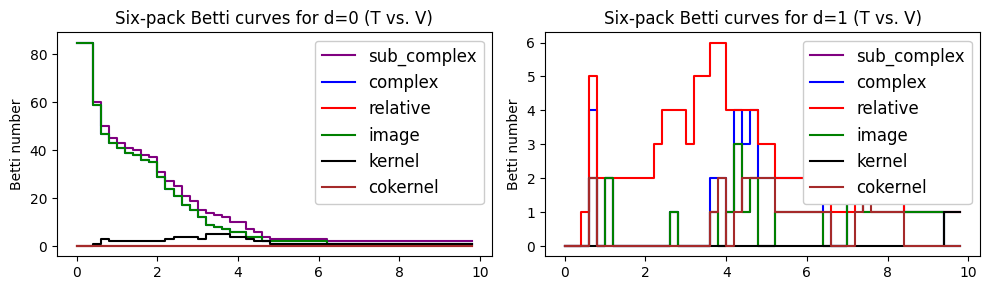

In [24]:
labels = ['sub_complex','complex','relative','image','kernel','cokernel']
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

for i in range(6):
    axes[0].step(x_vector, TV0[i], where="post", color=colors[i], label=labels[i])
axes[0].set_title('Six-pack Betti curves for d=0 (T vs. V)')
axes[0].set_xlabel('')
axes[0].set_ylabel('Betti number')
axes[0].legend(fontsize=12, framealpha=1.0)

for i in range(6):
    axes[1].step(x_vector, TV1[i], where="post", color=colors[i], label=labels[i])
axes[1].set_title('Six-pack Betti curves for d=1 (T vs. V)')
axes[1].set_xlabel('')
axes[1].set_ylabel('Betti number')
axes[1].legend(fontsize=12, framealpha=1.0)

plt.tight_layout()
plt.savefig(f'plots/id_{x}_t_{t}_tv_sixpack.pdf')
plt.show()

In [25]:
MV0 = np.vstack([
    sp.iloc[0,1203:1253].to_numpy(),
    sp.iloc[0,1253:1303].to_numpy(),
    sp.iloc[0,1303:1353].to_numpy(),
    sp.iloc[0,1353:1403].to_numpy(),
    sp.iloc[0,1403:1453].to_numpy(),
    sp.iloc[0,1453:1503].to_numpy()
])
MV1 = np.vstack([
    sp.iloc[0,1503:1553].to_numpy(),
    sp.iloc[0,1553:1603].to_numpy(),
    sp.iloc[0,1603:1653].to_numpy(),
    sp.iloc[0,1653:1703].to_numpy(),
    sp.iloc[0,1703:1753].to_numpy(),
    sp.iloc[0,1753:1803].to_numpy()
])

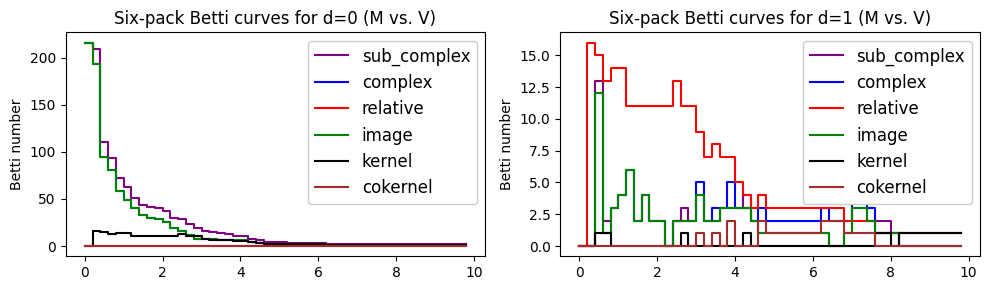

In [26]:
labels = ['sub_complex','complex','relative','image','kernel','cokernel']
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

for i in range(6):
    axes[0].step(x_vector, MV0[i], where="post", color=colors[i], label=labels[i])
axes[0].set_title('Six-pack Betti curves for d=0 (M vs. V)')
axes[0].set_xlabel('')
axes[0].set_ylabel('Betti number')
axes[0].legend(fontsize=12, framealpha=1.0)

for i in range(6):
    axes[1].step(x_vector, MV1[i], where="post", color=colors[i], label=labels[i])
axes[1].set_title('Six-pack Betti curves for d=1 (M vs. V)')
axes[1].set_xlabel('')
axes[1].set_ylabel('Betti number')
axes[1].legend(fontsize=12, framealpha=1.0)

plt.tight_layout()
plt.savefig(f'plots/id_{x}_t_{t}_mv_sixpack.pdf')
plt.show()

### Ripley's K estimator

In [27]:
Mrk = rk.iloc[0,3:53].to_numpy()
Trk = rk.iloc[0,53:103].to_numpy()
Vrk = rk.iloc[0,103:153].to_numpy()

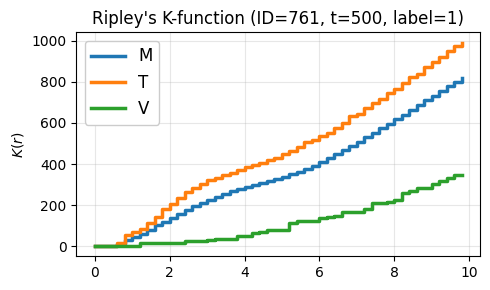

In [28]:
plt.figure(figsize=(5, 3))
plt.step(x_vector, Mrk, where='post', linewidth=2.5, label='M')
plt.step(x_vector, Trk, where='post', linewidth=2.5, label='T')
plt.step(x_vector, Vrk, where='post', linewidth=2.5, label='V')

plt.ylabel("$K(r)$")
plt.title(f"Ripley's K-function (ID={int(rk.iloc[0, 0])}, t={int(rk.iloc[0, 1])}, label={int(rk.iloc[0, 2])})")
plt.legend(fontsize=12, framealpha=1.0)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f'plots/id_{x}_t_{t}_ripleyk.pdf')
plt.show()